# Semantic Clustering of Scientific Publications Using SBERT and KMeans

**Course:** Multi-LLM Architectures and Eco-Responsible AI  
**Lab Activity:** 02 – Semantic Analysis using SBERT  
**Level:** MSc AI (M2)

## 1. Introduction

Scientific publications are continuously increasing in number, making it difficult for researchers to identify relevant studies and discover relationships between research topics.

Traditional text analysis methods, such as Bag-of-Words and TF-IDF, mainly rely on word frequency and may fail to recognize semantic relationships between texts that use different vocabulary but express similar concepts.

In this project, we investigate semantic analysis using Sentence-BERT (SBERT), a Transformer-based model that converts scientific publications into dense numerical representations called embeddings.

The generated embeddings are analyzed using cosine similarity and KMeans clustering to identify semantically related scientific publications.

## 2. Problem Statement

The objective is to automatically organize scientific publications into groups according to their semantic content rather than relying exclusively on keywords or predefined categories.

## 3. Objectives

- Load and preprocess a scientific publication dataset.
- Generate semantic embeddings using SBERT.
- Measure semantic similarity using cosine similarity.
- Group publications using KMeans clustering.
- Visualize clusters using PCA.
- Interpret the resulting groups using representative publications, important terms and arXiv categories.
- Discuss the limitations and environmental considerations of the approach.

## 4. Methodology

The selected embedding model is `sentence-transformers/all-MiniLM-L6-v2`.

Each publication is represented by a 384-dimensional vector. These embeddings are used for semantic similarity analysis and unsupervised clustering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Define project paths
DATA_PATH = Path("../data")
OUTPUT_PATH = Path("../outputs")

# Load the scientific publications dataset
df = pd.read_csv(DATA_PATH / "publications.csv")

print("Dataset successfully loaded!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset successfully loaded!
Dataset shape: (1000, 4)


,paper_id,title,abstract,categories
0,http://arxiv.org/abs/1806.00047v1,Following High-level Navigation Instructions o...,We introduce a method for following high-level...,"cs.AI, cs.CL, cs.CV, cs.LG, cs.RO"
1,http://arxiv.org/abs/1902.09705v1,Beyond the Self: Using Grounded Affordances to...,We propose a developmental approach that allow...,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG"
2,http://arxiv.org/abs/2011.07384v1,Few-shot Object Grounding and Mapping for Natu...,We study the problem of learning a robot polic...,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG"
3,http://arxiv.org/abs/2401.08577v1,MultiPLY: A Multisensory Object-Centric Embodi...,Human beings possess the capability to multipl...,"cs.CV, cs.AI, cs.CL, cs.LG, cs.RO"
4,http://arxiv.org/abs/2311.17593v1,LanGWM: Language Grounded World Model,Recent advances in deep reinforcement learning...,"cs.LG, cs.AI, cs.CL, cs.CV, cs.RO"


## 5. Dataset Exploration

In this section, we examine the structure and quality of the scientific publications dataset before applying semantic analysis.

We investigate the dataset dimensions, column types, missing values, duplicate records, abstract lengths and distribution of research categories.

This step helps us understand the dataset and identify potential preprocessing requirements.

In [2]:

# Display dataset information
print("Dataset information:")
df.info()

# Check missing values
print("\nMissing values:")
display(df.isnull().sum())

# Check duplicate paper IDs
print("\nDuplicate paper IDs:")
print(df["paper_id"].duplicated().sum())

# Calculate abstract lengths
df["abstract_length"] = df["abstract"].str.len()

print("\nAbstract length statistics:")
display(df["abstract_length"].describe())

# Analyze category distribution
category_counts = (
    df["categories"]
    .str.split(", ")
    .explode()
    .value_counts()
)

print("\nMost frequent research categories:")
display(category_counts.head(10))


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   paper_id    1000 non-null   str  
 1   title       1000 non-null   str  
 2   abstract    1000 non-null   str  
 3   categories  1000 non-null   str  
dtypes: str(4)
memory usage: 1.4 MB

Missing values:


paper_id      0
title         0
abstract      0
categories    0
dtype: int64


Duplicate paper IDs:
0

Abstract length statistics:


count    1000.000000
mean     1290.794000
std       303.555549
min       141.000000
25%      1090.000000
50%      1282.000000
75%      1486.250000
max      1921.000000
Name: abstract_length, dtype: float64


Most frequent research categories:


categories
cs.AI      991
cs.LG      969
cs.CV      968
cs.CL      600
cs.RO      573
cs.MM       42
stat.ML     39
cs.HC       29
cs.NE       21
cs.GR       19
Name: count, dtype: int64

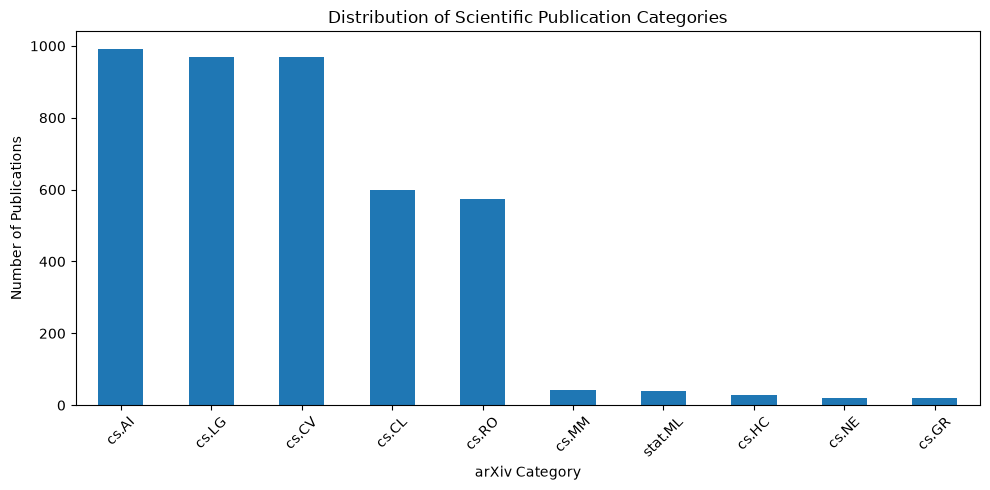

In [3]:
plt.figure(figsize=(10, 5))

category_counts.head(10).plot(
    kind="bar"
)

plt.title("Distribution of Scientific Publication Categories")
plt.xlabel("arXiv Category")
plt.ylabel("Number of Publications")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Dataset exploration confirms that the collection contains 1,000 scientific publications. The dataset includes publication identifiers, titles, abstracts and research categories. Missing values and duplicate records were examined to assess data quality. Abstract lengths were also analyzed to understand the textual characteristics of the dataset. The category distribution provides an overview of the research domains represented in the collection.

### 5.1 Interpretation of Dataset Exploration

The dataset contains 1,000 scientific publications and four columns: paper ID, title, abstract and categories.

The quality analysis revealed no missing values and no duplicate paper identifiers. The average abstract length is approximately 1,291 characters, with a minimum of 141 and a maximum of 1,921 characters.

The category distribution indicates that the dataset is mainly composed of publications related to Artificial Intelligence (cs.AI), Machine Learning (cs.LG), Computer Vision (cs.CV), Natural Language Processing (cs.CL) and Robotics (cs.RO).

Since arXiv supports multiple categories per publication, category counts are not mutually exclusive.

Overall, the dataset provides a suitable textual collection for exploring semantic relationships between scientific publications. However, its concentration in several AI-related categories should be considered when interpreting the clustering results.

## 6. Text Cleaning and Preprocessing

Before generating semantic embeddings, the textual data must be prepared.

Scientific abstracts may contain unnecessary whitespace, line breaks and formatting inconsistencies.

The preprocessing stage consists of:

1. Removing missing titles and abstracts.
2. Removing duplicate publications.
3. Normalizing whitespace.
4. Cleaning titles and abstracts.
5. Combining titles and abstracts into a single text representation.

We preserve stop words, punctuation and sentence structure because SBERT uses contextual information to understand the meaning of text.

In [5]:

import re

# Work on a copy of the original dataset
df_clean = df.copy()

# 1. Remove missing titles and abstracts
df_clean = df_clean.dropna(
    subset=["title", "abstract"]
).copy()

# 2. Remove duplicate publications
df_clean = df_clean.drop_duplicates(
    subset=["paper_id"]
).copy()

# 3. Define the text cleaning function
def clean_text(text):

    text = str(text)

    # Normalize unnecessary whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing spaces
    text = text.strip()

    return text

# 4. Clean titles
df_clean["title_clean"] = (
    df_clean["title"].apply(clean_text)
)

# 5. Clean abstracts
df_clean["abstract_clean"] = (
    df_clean["abstract"].apply(clean_text)
)

# 6. Remove empty abstracts
df_clean = df_clean[
    df_clean["abstract_clean"].str.len() > 0
].copy()

# 7. Combine title and abstract
df_clean["text_clean"] = (
    df_clean["title_clean"]
    + ". "
    + df_clean["abstract_clean"]
)

# Display results
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("\nExample cleaned publication:")
print(df_clean["text_clean"].iloc[0])

# Save cleaned dataset
df_clean.to_csv(
    DATA_PATH / "publications_cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")


Original dataset: (1000, 5)
Cleaned dataset: (1000, 8)

Example cleaned publication:
Following High-level Navigation Instructions on a Simulated Quadcopter with Imitation Learning. We introduce a method for following high-level navigation instructions by mapping directly from images, instructions and pose estimates to continuous low-level velocity commands for real-time control. The Grounded Semantic Mapping Network (GSMN) is a fully-differentiable neural network architecture that builds an explicit semantic map in the world reference frame by incorporating a pinhole camera projection model within the network. The information stored in the map is learned from experience, while the local-to-world transformation is computed explicitly. We train the model using DAggerFM, a modified variant of DAgger that trades tabular convergence guarantees for improved training speed and memory use. We test GSMN in virtual environments on a realistic quadcopter simulator and show that incorporating an e

In [6]:
df_clean[[
    "paper_id",
    "title_clean",
    "abstract_clean",
    "text_clean"
]].head()

,paper_id,title_clean,abstract_clean,text_clean
0,http://arxiv.org/abs/1806.00047v1,Following High-level Navigation Instructions o...,We introduce a method for following high-level...,Following High-level Navigation Instructions o...
1,http://arxiv.org/abs/1902.09705v1,Beyond the Self: Using Grounded Affordances to...,We propose a developmental approach that allow...,Beyond the Self: Using Grounded Affordances to...
2,http://arxiv.org/abs/2011.07384v1,Few-shot Object Grounding and Mapping for Natu...,We study the problem of learning a robot polic...,Few-shot Object Grounding and Mapping for Natu...
3,http://arxiv.org/abs/2401.08577v1,MultiPLY: A Multisensory Object-Centric Embodi...,Human beings possess the capability to multipl...,MultiPLY: A Multisensory Object-Centric Embodi...
4,http://arxiv.org/abs/2311.17593v1,LanGWM: Language Grounded World Model,Recent advances in deep reinforcement learning...,LanGWM: Language Grounded World Model. Recent ...


## 7. Semantic Embedding Generation Using SBERT

Sentence-BERT (SBERT) is a Transformer-based model designed to generate meaningful numerical representations of sentences and documents.

In this project, we use the pretrained model `all-MiniLM-L6-v2`.

Each scientific publication is transformed into a 384-dimensional vector. These embeddings capture semantic information and allow publications to be compared based on their meaning.

To reduce unnecessary computational costs, we reuse the embeddings generated during the previous experiment and saved in NumPy format.

In [7]:

# Load previously generated SBERT embeddings

embeddings_path = (
    OUTPUT_PATH / "embeddings" / "sbert_embeddings.npy"
)

embeddings = np.load(embeddings_path)

print("Embedding matrix shape:", embeddings.shape)
print("Number of publications:", embeddings.shape[0])
print("Embedding dimensions:", embeddings.shape[1])

# Inspect the first five numerical values
print("\nFirst five embedding values:")
print(embeddings[0][:5])


Embedding matrix shape: (1000, 384)
Number of publications: 1000
Embedding dimensions: 384

First five embedding values:
[ 0.05057996 -0.07688721  0.00903454 -0.02786981 -0.07345314]


In [8]:
# Verify that all embeddings are finite
print("All embeddings are finite:",
      np.isfinite(embeddings).all())

# Verify vector normalization
norms = np.linalg.norm(embeddings, axis=1)

print("Average embedding norm:", norms.mean())

All embeddings are finite: True
Average embedding norm: 1.0


### 7.1 Interpretation of SBERT Embeddings

The SBERT model successfully transformed the 1,000 scientific publications into a numerical matrix of shape (1000, 384).

Each row represents one publication, while the 384 columns represent the dimensions of its semantic embedding.

These dense vectors encode contextual information about the publications and provide the numerical representations required for semantic similarity and clustering.

The embeddings were normalized and saved for reuse, avoiding repeated model inference and reducing computational costs.

## 8. Semantic Similarity Using Cosine Similarity

Cosine similarity is used to measure the semantic similarity between scientific publications based on their SBERT embeddings.

It measures the cosine of the angle between two numerical vectors. Higher similarity scores indicate that two publications have more similar semantic representations.

In this experiment, we calculate the similarity between all publications and retrieve the five most similar publications to a selected reference paper.

In [9]:

from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity between all publications
similarity_matrix = cosine_similarity(embeddings)

print("Similarity matrix shape:", similarity_matrix.shape)

# Select the first publication as reference
reference_index = 0

print("\nReference publication:")
print(df_clean.iloc[reference_index]["title"])

# Extract similarity scores
similarities = similarity_matrix[reference_index]

# Find the five most similar publications
# Exclude the reference publication itself
similar_indices = np.argsort(similarities)[::-1][1:6]

results = []

for index in similar_indices:
    results.append({
        "Title": df_clean.iloc[index]["title"],
        "Similarity": round(float(similarities[index]), 4),
        "Categories": df_clean.iloc[index]["categories"]
    })

similarity_results = pd.DataFrame(results)

display(similarity_results)


Similarity matrix shape: (1000, 1000)

Reference publication:
Following High-level Navigation Instructions on a Simulated Quadcopter with Imitation Learning


,Title,Similarity,Categories
0,Mapping Navigation Instructions to Continuous ...,0.7392,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG"
1,Learning to Map Natural Language Instructions ...,0.7356,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG"
2,Few-shot Object Grounding and Mapping for Natu...,0.7098,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG"
3,What Limits Vision-and-Language Navigation ?,0.6999,"cs.RO, cs.AI, cs.CL, cs.CV"
4,VLN on the Fly: An Onboard Vision-Language Nav...,0.6612,"cs.RO, cs.AI, cs.CV, cs.LG, eess.SY"


The cosine similarity experiment demonstrates that SBERT can identify scientific publications with related meanings, even when their titles use different wording. The five most similar publications to the reference paper focus on topics such as navigation instructions, natural language understanding, robot control, object grounding, and vision-and-language navigation.

The highest similarity score was **0.7392**, for the paper *“Mapping Navigation Instructions to Continuous Control Actions with Position-Visitation Prediction”*. The second-highest score was **0.7356**, for *“Learning to Map Natural Language Instructions to Physical Quadcopter Control using Simulated Flight”*. These results indicate a strong semantic relationship with the reference paper, particularly around language-guided navigation and quadcopter control.

All five retrieved publications share several research categories with the reference paper, including cs.RO, cs.AI, and cs.CV. This supports the observation that the model captures meaningful relationships between research topics.

Overall, the results show that SBERT embeddings combined with cosine similarity can be used to retrieve semantically related scientific publications. This provides a foundation for the next experiment, in which the embeddings will be grouped into clusters using KMeans.

### 8.1 Interpretation of Semantic Similarity

The cosine similarity experiment demonstrates the ability of SBERT to identify semantically related scientific publications.

The reference publication focuses on high-level navigation instructions and imitation learning for quadcopter control.

The five most similar publications address related topics, including natural language navigation, continuous control, robot instruction following and vision-language navigation.

The similarity scores range from 0.6612 to 0.7392. These results suggest that SBERT can identify meaningful relationships between publications even when they use different vocabulary.

## 9. Semantic Clustering Using KMeans

In this experiment, KMeans clustering is applied to the SBERT embeddings to group scientific publications according to their semantic similarities.

Unlike cosine similarity, which compares individual pairs of publications, clustering identifies broader groups of publications that share similar research themes.

Different values of K (number of clusters) will be tested, ranging from 2 to 10. The silhouette score with cosine distance will be used to evaluate the quality of each clustering result. A higher silhouette score indicates better-defined clusters.

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

k_values = range(2, 11)
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(embeddings)

    score = silhouette_score(
        embeddings,
        cluster_labels,
        metric="cosine"
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.1318
K = 3, Silhouette Score = 0.1120
K = 4, Silhouette Score = 0.0998
K = 5, Silhouette Score = 0.0668
K = 6, Silhouette Score = 0.0700
K = 7, Silhouette Score = 0.0572
K = 8, Silhouette Score = 0.0442
K = 9, Silhouette Score = 0.0466
K = 10, Silhouette Score = 0.0460


### 9.1 Comparison of Silhouette Scores

The silhouette scores are compared across different values of K to identify the most suitable number of clusters. The value of K with the highest silhouette score is selected for the final KMeans model.

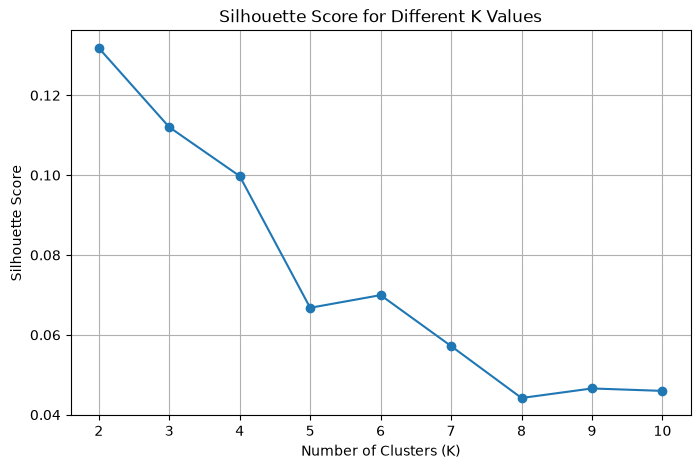

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### 9.4 Final KMeans Clustering

Based on the silhouette score comparison, K=2 is selected for the final clustering experiment because it achieved the highest score of 0.1318 among the tested values.

The KMeans model is fitted again using two clusters, and each scientific publication is assigned a cluster label.

In [12]:
best_k = 2

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(embeddings)

df_clustered = df_clean.copy()
df_clustered["cluster"] = cluster_labels

print("Selected number of clusters:", best_k)
print("\nNumber of publications in each cluster:")
print(df_clustered["cluster"].value_counts().sort_index())

display(
    df_clustered[["title", "categories", "cluster"]].head(10)
)

Selected number of clusters: 2

Number of publications in each cluster:
cluster
0    552
1    448
Name: count, dtype: int64


,title,categories,cluster
0,Following High-level Navigation Instructions o...,"cs.AI, cs.CL, cs.CV, cs.LG, cs.RO",0
1,Beyond the Self: Using Grounded Affordances to...,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG",0
2,Few-shot Object Grounding and Mapping for Natu...,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG",0
3,MultiPLY: A Multisensory Object-Centric Embodi...,"cs.CV, cs.AI, cs.CL, cs.LG, cs.RO",0
4,LanGWM: Language Grounded World Model,"cs.LG, cs.AI, cs.CL, cs.CV, cs.RO",0
5,Grounded Decoding: Guiding Text Generation wit...,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG",0
6,CALVIN: A Benchmark for Language-Conditioned P...,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG",0
7,RT-1: Robotics Transformer for Real-World Cont...,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG",0
8,Audio Visual Language Maps for Robot Navigation,"cs.RO, cs.AI, cs.CL, cs.CV, cs.LG",0
9,Can Visual Context Improve Automatic Speech Re...,"eess.AS, cs.AI, cs.CL, cs.CV, cs.LG, cs.RO",0


The final KMeans model divided the 1,000 scientific publications into two clusters.

- **Cluster 0:** 552 publications (55.2%)
- **Cluster 1:** 448 publications (44.8%)

The distribution indicates that the dataset has been divided into two relatively balanced groups. The first ten displayed publications were assigned to Cluster 0. Their titles suggest research themes involving robotics, navigation, language-guided control, object grounding, and embodied AI.

However, the cluster labels alone do not explain the complete research themes of both groups. Further analysis of representative publications and important terms in each cluster is required to interpret them.

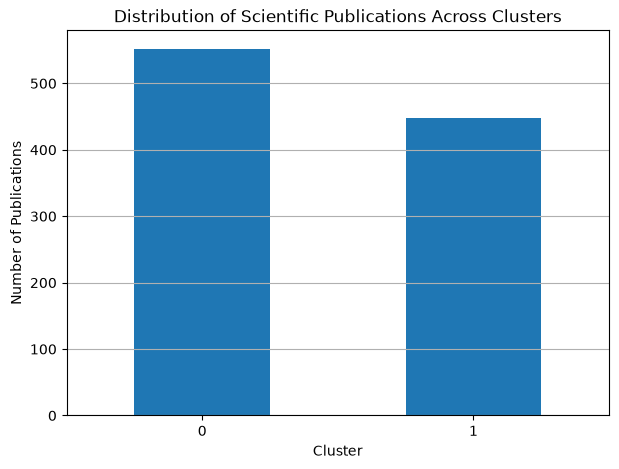

In [13]:
cluster_counts = df_clustered["cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
cluster_counts.plot(kind="bar")

plt.xlabel("Cluster")
plt.ylabel("Number of Publications")
plt.title("Distribution of Scientific Publications Across Clusters")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [14]:
clustered_path = OUTPUT_PATH / "publications_clustered.csv"

df_clustered.to_csv(clustered_path, index=False)

print("Clustered dataset saved to:", clustered_path)

Clustered dataset saved to: ../outputs/publications_clustered.csv


The bar chart illustrates the distribution of scientific publications across the two clusters generated by KMeans. Cluster 0 contains 552 publications (55.2%), while Cluster 1 contains 448 publications (44.8%). The distribution is relatively balanced, indicating that neither cluster dominates the dataset. However, the cluster sizes alone do not reveal the semantic themes represented by each group. Further analysis is required to identify the main research topics within each cluster.

## 10. Visualisation of Clusters Using PCA

Principal Component Analysis (PCA) is a dimensionality reduction technique that transforms high-dimensional data into a smaller number of dimensions while preserving as much variance as possible.

In this experiment, PCA is used to reduce the 384-dimensional SBERT embeddings to two dimensions. The resulting two-dimensional representation is visualised using a scatter plot, with different colours representing the KMeans clusters.

PCA is used only for visualisation. The original SBERT embeddings are retained for KMeans clustering.

In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

embeddings_2d = pca.fit_transform(embeddings)

print("Original embedding shape:", embeddings.shape)
print("PCA embedding shape:", embeddings_2d.shape)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Original embedding shape: (1000, 384)
PCA embedding shape: (1000, 2)
Explained variance ratio: [0.08815373 0.05359447]
Total explained variance: 0.1417482


PCA successfully reduced the SBERT embeddings from 384 dimensions to two principal components. The first principal component explains approximately 8.82% of the variance, while the second explains approximately 5.36%. Together, the two components retain approximately 14.17% of the total variance in the original embeddings.

This indicates that the two-dimensional representation captures only a portion of the information contained in the original embeddings. However, it provides a useful way to visualise the overall distribution of publications and examine the clustering structure. Some semantic relationships may not be visible in this reduced representation.

### 10.2 Two-Dimensional Visualisation of Clusters

A scatter plot is generated using the two principal components obtained from PCA. Each point represents a scientific publication, and its colour indicates the cluster assigned by KMeans.

This visualisation helps examine the distribution and potential overlap between the two clusters.

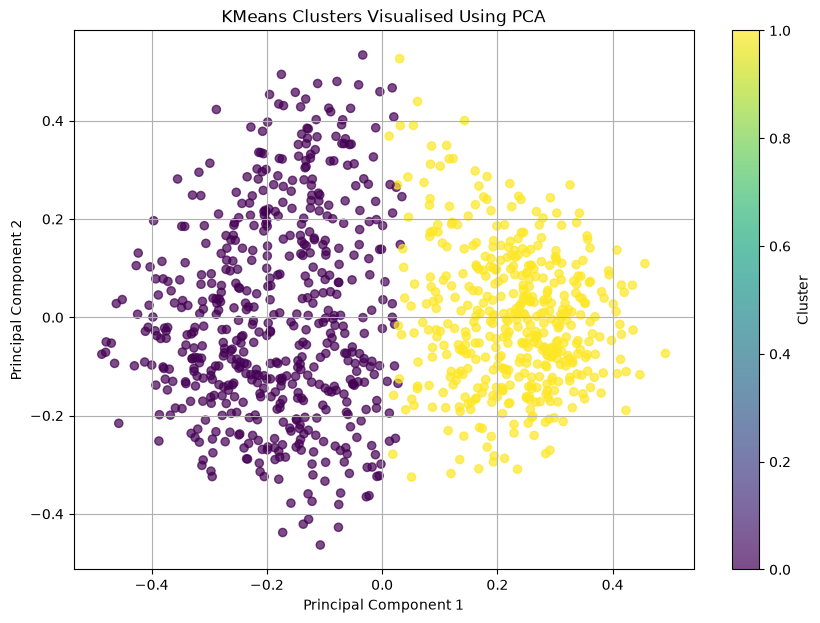

In [16]:
plt.figure(figsize=(10, 7))

plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=cluster_labels,
    cmap="viridis",
    alpha=0.7,
    s=35
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("KMeans Clusters Visualised Using PCA")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

The PCA scatter plot visualises the 1,000 scientific publications using two principal components. Each point represents one publication, and its colour indicates the cluster assigned by KMeans.

The plot shows that Cluster 0 (purple) is concentrated mainly on the left side, while Cluster 1 (yellow) is concentrated mainly on the right side. There is some overlap near the centre, indicating that certain publications have similar semantic characteristics despite being assigned to different clusters.

The visible separation suggests that the KMeans model has identified two broad groups with different semantic patterns. However, the two-dimensional PCA representation explains only approximately 14.17% of the total variance. Therefore, this plot provides a simplified view of the original 384-dimensional embedding space and should not be treated as a complete representation of cluster separation.

## 11. Cluster Interpretation and Semantic Analysis

KMeans assigns a numerical label to each publication but does not automatically identify the research themes represented by each cluster.

To interpret the clusters, representative publication titles, important keywords, and arXiv category distributions are examined. This helps identify the dominant research topics and understand the semantic differences between the two groups.

### 11.1 Representative Publications in Each Cluster

The publication titles within each cluster are examined to identify common research themes. A sample of publications from each cluster is displayed to support qualitative interpretation.

In [17]:
for cluster_id in sorted(df_clustered["cluster"].unique()):
    print(f"\n{'='*70}")
    print(f"CLUSTER {cluster_id}")
    print(f"{'='*70}")

    cluster_papers = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    for i, title in enumerate(
        cluster_papers["title"].head(10),
        start=1
    ):
        print(f"{i}. {title}")


CLUSTER 0
1. Following High-level Navigation Instructions on a Simulated Quadcopter with Imitation Learning
2. Beyond the Self: Using Grounded Affordances to Interpret and Describe Others' Actions
3. Few-shot Object Grounding and Mapping for Natural Language Robot Instruction Following
4. MultiPLY: A Multisensory Object-Centric Embodied Large Language Model in 3D World
5. LanGWM: Language Grounded World Model
6. Grounded Decoding: Guiding Text Generation with Grounded Models for Embodied Agents
7. CALVIN: A Benchmark for Language-Conditioned Policy Learning for Long-Horizon Robot Manipulation Tasks
8. RT-1: Robotics Transformer for Real-World Control at Scale
9. Audio Visual Language Maps for Robot Navigation
10. Can Visual Context Improve Automatic Speech Recognition for an Embodied Agent?

CLUSTER 1
1. Lexicon3D: Probing Visual Foundation Models for Complex 3D Scene Understanding
2. YOLO with Kolmogorov-Arnold networks and vision-language foundation models for interpretable object d

The representative publications suggest that the two clusters contain different but related research themes.

**Cluster 0** appears to focus on robotics and embodied AI. Its publications include topics such as language-guided robot navigation, object grounding, robot manipulation, embodied agents, and real-world robotic control.

**Cluster 1** appears to focus more broadly on vision-language models and multimodal visual understanding. Its publications cover topics such as 3D scene understanding, object detection, video understanding, visual foundation models, and vision-language model adaptation.

This initial comparison suggests that KMeans has identified two broad semantic groups within the scientific publication dataset. Further keyword analysis is required to validate and refine these interpretations.

### 11.3 Keyword Extraction Using TF-IDF

TF-IDF is used to identify important words and phrases within each cluster. It assigns higher weights to terms that are frequent in a particular group of documents but less common across the entire dataset.

The average TF-IDF scores of terms are calculated separately for each cluster. The highest-scoring terms help identify the dominant research topics and provide additional evidence for interpreting the clusters.

TF-IDF is used only for cluster interpretation and does not affect the original SBERT embeddings or KMeans clustering.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Extract TF-IDF features from cleaned publication text
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=3000,
    ngram_range=(1, 2)
)

tfidf_matrix = vectorizer.fit_transform(
    df_clustered["text_clean"]
)

feature_names = vectorizer.get_feature_names_out()

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (1000, 3000)


In [19]:
for cluster_id in sorted(df_clustered["cluster"].unique()):

    cluster_indices = (
        df_clustered["cluster"] == cluster_id
    ).values

    cluster_tfidf = tfidf_matrix[cluster_indices]

    mean_scores = np.asarray(
        cluster_tfidf.mean(axis=0)
    ).flatten()

    top_indices = mean_scores.argsort()[::-1][:15]

    print(f"\n{'='*50}")
    print(f"TOP KEYWORDS - CLUSTER {cluster_id}")
    print(f"{'='*50}")

    for index in top_indices:
        print(
            f"{feature_names[index]}: "
            f"{mean_scores[index]:.4f}"
        )


TOP KEYWORDS - CLUSTER 0
learning: 0.0408
robot: 0.0351
3d: 0.0328
language: 0.0323
tasks: 0.0288
world: 0.0285
object: 0.0281
agent: 0.0278
navigation: 0.0273
model: 0.0257
data: 0.0251
based: 0.0250
real: 0.0244
models: 0.0243
objects: 0.0233

TOP KEYWORDS - CLUSTER 1
models: 0.0509
language: 0.0430
multimodal: 0.0398
image: 0.0374
visual: 0.0371
model: 0.0369
text: 0.0352
data: 0.0272
vision: 0.0266
reasoning: 0.0257
tasks: 0.0238
learning: 0.0234
language models: 0.0229
training: 0.0228
large: 0.0221


The TF-IDF keyword analysis provides further evidence of the semantic differences between the two clusters.

**Cluster 0** contains prominent terms such as learning, robot, 3D, language, tasks, object, agent, and navigation. These keywords indicate that this cluster is strongly associated with robotics, embodied AI, object interaction, and language-guided navigation.

**Cluster 1** contains prominent terms such as models, language, multimodal, image, visual, text, vision, and reasoning. These keywords suggest a stronger focus on vision-language models, multimodal learning, image and text understanding, and visual reasoning.

The keyword analysis broadly supports the interpretations obtained from the representative publication titles. Together, these findings suggest that SBERT embeddings and KMeans have grouped publications according to meaningful semantic patterns.

TF-IDF is used here to interpret the clusters rather than to determine their membership.

### 11.5 Distribution of arXiv Categories Across Clusters

The arXiv category metadata is analysed to understand the research areas represented in each cluster.

Since a publication can belong to multiple arXiv categories, category percentages are calculated as the proportion of publications in each cluster that contain a particular category. Therefore, the percentages do not necessarily add up to 100%.

In [20]:
# Extract category counts for each cluster
for cluster_id in sorted(df_clustered["cluster"].unique()):

    cluster_df = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    category_counts = (
        cluster_df["categories"]
        .str.split(", ")
        .explode()
        .value_counts()
    )

    category_percentages = (
        category_counts / len(cluster_df) * 100
    )

    print(f"\n{'='*50}")
    print(f"TOP ARXIV CATEGORIES - CLUSTER {cluster_id}")
    print(f"{'='*50}")

    display(
        category_percentages.head(10)
        .round(2)
        .rename("Percentage of Publications (%)")
        .to_frame()
    )


TOP ARXIV CATEGORIES - CLUSTER 0


,Percentage of Publications (%)
categories,
cs.AI,98.73
cs.CV,95.11
cs.LG,95.11
cs.RO,93.84
cs.CL,33.15
stat.ML,4.71
eess.SY,3.44
cs.HC,2.90
cs.GR,2.54



TOP ARXIV CATEGORIES - CLUSTER 1


,Percentage of Publications (%)
categories,
cs.AI,99.55
cs.LG,99.11
cs.CV,98.88
cs.CL,93.08
cs.RO,12.28
cs.MM,8.48
cs.CY,3.35
cs.IR,3.12
stat.ML,2.90


The arXiv category analysis provides further insight into the research areas represented by each cluster.

**Cluster 0** has a high proportion of publications in cs.RO (93.84%), indicating a strong association with robotics. It also contains publications from cs.AI (98.73%), cs.CV (95.11%), and cs.LG (95.11%). This supports the interpretation that Cluster 0 is primarily associated with robotics, embodied AI, and language-guided interaction.

**Cluster 1** has a much higher proportion of publications in cs.CL (93.08%) compared with Cluster 0 (33.15%). Only 12.28% of its publications belong to cs.RO, compared with 93.84% in Cluster 0. This suggests that Cluster 1 is more strongly associated with language technologies, vision-language models, and multimodal AI.

Both clusters contain very high proportions of cs.AI, cs.CV, and cs.LG publications. Therefore, these categories are common across the dataset and are less useful for distinguishing the two groups.

Since arXiv categories are multi-label, individual publications can belong to several categories. The percentages represent category coverage within each cluster and do not need to sum to 100%.

Overall, the category distribution supports the distinctions identified through representative titles and TF-IDF keywords.

## 12. Overall Results, Discussion and Conclusion

This section summarises the results obtained from semantic analysis and clustering of scientific publications using Sentence-BERT embeddings.

The experiments included semantic similarity retrieval, KMeans clustering, PCA visualisation, and cluster interpretation using TF-IDF keywords and arXiv categories.

The experiments demonstrate how Sentence-BERT can transform scientific publications into semantic embeddings that support similarity retrieval and clustering.

The cosine similarity experiment successfully retrieved publications related to the reference paper, particularly those concerning robot navigation, natural language instructions, and quadcopter control. The highest similarity score was 0.7392.

KMeans clustering divided the 1,000 publications into two groups. The best silhouette score among the tested values of K=2 to K=10 was 0.1318, obtained with K=2. Although this was the highest score, its relatively low value indicates that the clusters have overlapping semantic characteristics and are not sharply separated.

PCA reduced the 384-dimensional embeddings to two dimensions for visualisation. The two principal components explained 14.17% of the total variance, providing a simplified representation of the clustering structure.

Cluster interpretation using representative titles, TF-IDF keywords, and arXiv categories suggested two broad research themes: robotics and embodied AI in Cluster 0, and vision-language and multimodal AI in Cluster 1.

Overall, the experiments demonstrate that SBERT embeddings can capture semantic relationships between scientific publications and provide a useful foundation for organising research literature into meaningful groups.

The project has several limitations:

1. **Dataset size:** The experiment uses 1,000 publications, which may not represent the full diversity of scientific research.
2. **Embedding limitations:** The all-MiniLM-L6-v2 model has a maximum sequence length of 256 tokens, so longer abstracts may be truncated.
3. **Cluster overlap:** The best silhouette score was 0.1318, indicating limited separation between clusters.
4. **PCA information loss:** The two-dimensional PCA representation retains only 14.17% of the total variance.
5. **Multi-label categories:** Publications can belong to multiple arXiv categories, making category-based interpretation more complex.
6. **Cluster interpretation:** The descriptive cluster labels are based on representative titles, TF-IDF keywords, and category distributions rather than manually verified labels for every publication.

This project considers computational efficiency and resource usage when applying semantic AI techniques.

The Sentence-BERT model all-MiniLM-L6-v2 is a relatively lightweight sentence embedding model. Embeddings were generated in batches and saved to disk so that repeated experiments could reuse the same representations without running model inference again.

The experiments also used the Apple Silicon MPS device when available, allowing computation to utilise supported hardware acceleration.

Reusing embeddings for cosine similarity, KMeans clustering, and PCA avoids unnecessary repeated model execution. These practices help reduce redundant computation and support more resource-conscious AI experimentation.

However, this project did not directly measure energy consumption or carbon emissions. Therefore, its environmental benefits are discussed in terms of computational efficiency rather than quantified environmental impact.

This project successfully demonstrated semantic analysis and clustering of scientific publications using Sentence-BERT embeddings.

The results show that SBERT can identify semantically related publications and represent their research content as dense numerical vectors. KMeans clustering identified two broad groups, which were interpreted as robotics and embodied AI, and vision-language and multimodal AI.

Cosine similarity, silhouette evaluation, PCA visualisation, TF-IDF keyword extraction, and arXiv category analysis provided complementary ways to examine the dataset.

The project also demonstrated the importance of computational efficiency through batch processing and embedding reuse.

In conclusion, combining Sentence-BERT embeddings with traditional machine learning techniques provides a practical approach to semantic organisation and exploration of scientific literature.